# L1 refraction inversion results

Run all cells with the **refrapy-l1** kernel from the repository root. This notebook runs pyGIMLi traveltime tomography directly on the five stacked PASI records; it does **not** load a model calculated in the Refrainv GUI. It reuses the project's processing helpers and the same inversion engine used by Refrapy.

**Preliminary interpretation:** picks are automatic, not manually verified. Inspect the waveform panels before trusting the model. Geometry is a flat 2D line; the 47.5 m source override follows the existing RF notebook and must be confirmed against field notes. Ray paths indicate illumination, not a formal resolution or uncertainty estimate.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pygimli as pg
from IPython.display import display
from utils import seg2_io, refraction, plotting

DATA_FOLDER = Path('L1/RF')
OUTPUT_FOLDER = Path('L1/refrapy_inversion')
SOURCE_X_OVERRIDES = {'2026-10-08_RF_47.5m.dat': 47.5}
PICK_OVERRIDES = {}  # (shot_index, receiver_index): time_s; np.nan discards a pick
PICK_ERROR = 0.0035  # absolute timing uncertainty, seconds
MAX_RESIDUAL = 0.010  # QC rejection threshold, seconds
MESH_PARAMETERS = dict(para_dx=0.33, para_depth=12.0, quality=33.5,
                       max_cell_size=1.0, para_boundary=0.5)
INVERSION_PARAMETERS = dict(lam=100.0, z_weight=1.0, v_top=250.0,
                            v_bottom=1500.0, correlation_lengths=[80.0, 1.0])

if not DATA_FOLDER.is_dir():
    raise FileNotFoundError('Run this notebook from the repository root: L1/RF was not found.')
print(f'Interpreter: {sys.executable}\npyGIMLi: {pg.__version__}')
print('Preliminary automatic picks; review geometry and arrivals before interpretation.')

Interpreter: /home/orincon/miniconda3/envs/refrapy-l1/bin/python
pyGIMLi: 1.5.5
Preliminary automatic picks; review geometry and arrivals before interpretation.


In [2]:
gathers = seg2_io.read_line(str(DATA_FOLDER), source_x_overrides=SOURCE_X_OVERRIDES)
picks = refraction.pick_line(gathers, overrides=PICK_OVERRIDES, v_min=150.0,
                             v_max=1500.0, noise_window=0.010, threshold=3.0)
display(pd.DataFrame([dict(shot_index=i, file=g.filename, source_x_m=g.source_x,
                           receivers=g.n_receivers, sampling_hz=g.fs)
                      for i, g in enumerate(gathers)]))
display(refraction.picks_table(gathers, picks))

Read 5 shot gathers from L1/RF:
  2026-10-08_RF_-5m.dat: source at -5.0 m, 12 receivers (0.0-55.0 m), 4096 samples at 8000 Hz
  2026-10-08_RF_12.5m.dat: source at +12.5 m, 12 receivers (0.0-55.0 m), 4096 samples at 8000 Hz
  2026-10-08_RF_27.5m.dat: source at +27.5 m, 12 receivers (0.0-55.0 m), 4096 samples at 8000 Hz
  2026-10-08_RF_47.5m.dat: source at +47.5 m, 12 receivers (0.0-55.0 m), 4096 samples at 8000 Hz
  2026-10-08_RF_60m.dat: source at +60.0 m, 12 receivers (0.0-55.0 m), 4096 samples at 8000 Hz


,shot_index,file,source_x_m,receivers,sampling_hz
0,0,2026-10-08_RF_-5m.dat,-5.0,12,8000.0
1,1,2026-10-08_RF_12.5m.dat,12.5,12,8000.0
2,2,2026-10-08_RF_27.5m.dat,27.5,12,8000.0
3,3,2026-10-08_RF_47.5m.dat,47.5,12,8000.0
4,4,2026-10-08_RF_60m.dat,60.0,12,8000.0


,source -5.0 m,source +12.5 m,source +27.5 m,source +47.5 m,source +60.0 m
0.0 m,6.62,16.62,24.75,59.50,52.62
5.0 m,13.12,8.38,20.12,52.62,49.38
10.0 m,17.12,9.12,19.25,47.62,46.38
15.0 m,19.38,9.12,15.12,36.38,43.38
20.0 m,22.88,8.38,12.12,33.38,32.75
25.0 m,25.75,16.62,9.88,28.38,28.12
30.0 m,29.00,18.62,11.00,23.62,25.00
35.0 m,31.88,19.88,12.12,20.38,22.88
40.0 m,38.88,33.50,15.12,18.50,21.12
45.0 m,46.38,36.00,19.25,12.12,15.00


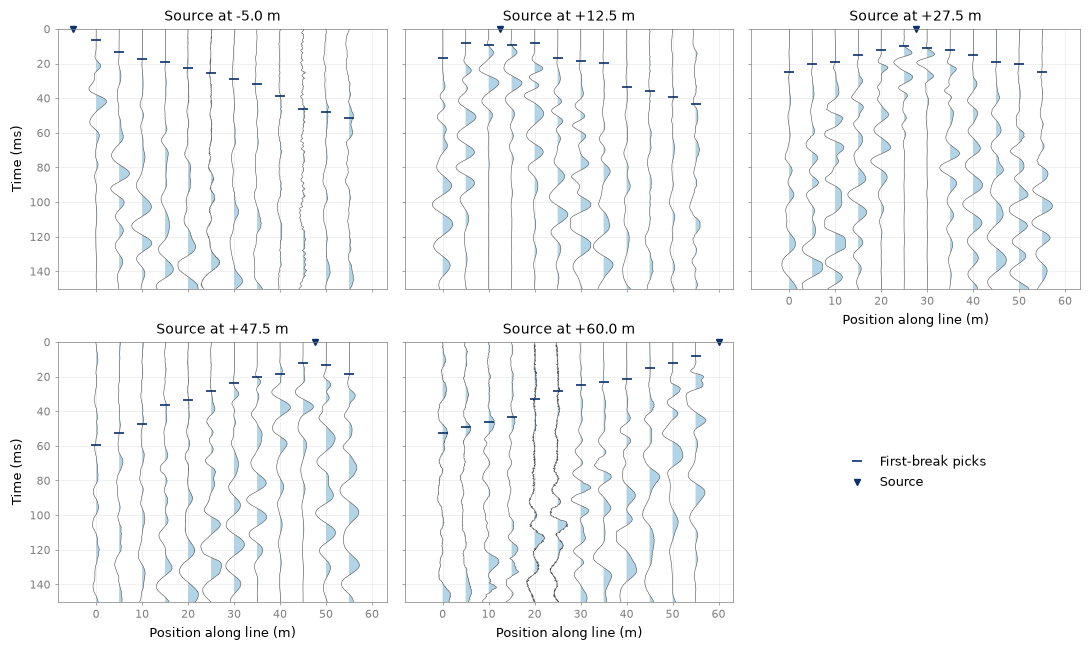

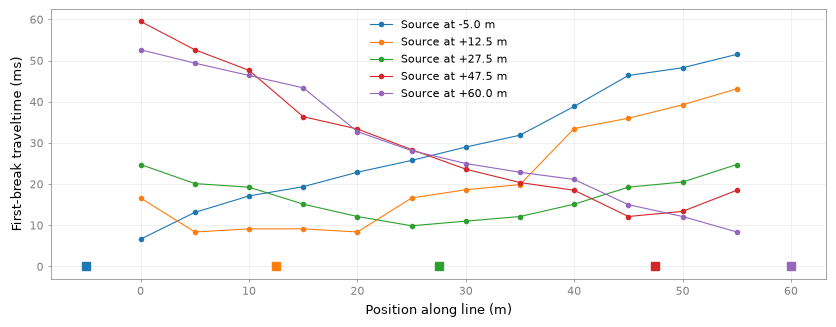

In [3]:
plotting.plot_all_gathers(gathers, picks_per_shot=picks, t_max=0.15,
                          ncols=3, width=11, fontsize=9)
plt.show()
plotting.plot_traveltime_curves(gathers, picks, width=10, height=3.5, fontsize=9)
plt.show()

## Two-pass tomography

The first fit flags picks with absolute residuals greater than 10 ms. The second fit uses the retained picks. Rejection is **model-dependent**, not proof that a pick is wrong: inspect every rejected arrival and revise `PICK_OVERRIDES` if needed. The 12 m model depth and strong horizontal correlation are assumptions, not measured resolution.

In [4]:
data_initial = refraction.build_traveltime_data(gathers, picks, pick_error=PICK_ERROR)
manager_qc = refraction.invert_tomography(data_initial, **MESH_PARAMETERS, **INVERSION_PARAMETERS)
picks_clean = refraction.drop_outlier_picks(
    gathers, picks, manager_qc, data_initial, max_residual=MAX_RESIDUAL)
rejected = pd.DataFrame([
    dict(shot_index=i, receiver_index=j, source_x_m=g.source_x,
         receiver_x_m=g.receiver_x[j], original_time_ms=t * 1000)
    for i, (g, original, cleaned) in enumerate(zip(gathers, picks, picks_clean))
    for j, t in enumerate(original) if np.isfinite(t) and np.isnan(cleaned[j])
], columns=['shot_index', 'receiver_index', 'source_x_m', 'receiver_x_m', 'original_time_ms'])
print(f'Rejected {len(rejected)} of {data_initial.size()} initial picks')
display(rejected)
data_clean = refraction.build_traveltime_data(gathers, picks_clean, pick_error=PICK_ERROR)
if data_clean.size() == 0:
    raise ValueError('QC rejected all picks; inspect arrivals and inversion settings.')
manager = refraction.invert_tomography(data_clean, **MESH_PARAMETERS, **INVERSION_PARAMETERS)
velocity = np.asarray(manager.velocity)
response = np.asarray(manager.inv.response)
if response.shape != np.asarray(data_clean['t']).shape or not np.all(np.isfinite(response)):
    raise ValueError('The inversion did not return a finite prediction for each retained pick.')
if not np.all(np.isfinite(velocity)) or np.any(velocity <= 0):
    raise ValueError('The inversion returned invalid velocities.')

24/10/26 - 18:26:50 - pyGIMLi - INFO - Found 1 regions.


24/10/26 - 18:26:50 - pyGIMLi - INFO - Found 1 regions.


24/10/26 - 18:26:50 - pyGIMLi - INFO - Creating forward mesh from region infos.


24/10/26 - 18:26:50 - pyGIMLi - INFO - Creating refined mesh (secnodes: 2) to solve forward task.


24/10/26 - 18:26:50 - pyGIMLi - INFO - Create gradient starting model. 250.0: 1500.0


...

Traveltime data: 17 sensors, 57 picks
Mesh: 1510 cells, 826 nodes (paraDX=0.33, depth=12.0 m, quality=33.5)


24/10/26 - 18:26:57 - pyGIMLi - INFO - Creating GeostatisticConstraintsMatrix for region 2 with: I=[80.0, 1.0], dip=0, strike=0


24/10/26 - 18:26:57 - pyGIMLi - INFO - Cache /home/orincon/miniconda3/envs/refrapy-l1/lib/python3.12/site-packages/pygimli/math/matrix.py:createCm05 restored (6.8s x 5): /home/orincon/.cache/pygimli/18182626742328715001


24/10/26 - 18:26:57 - Core - ERROR - no cWeights defined. You should create constraints matrix first.




Inversion finished: chi2 = 1.00, Vp = 373-1492 m/s (mean 1266 m/s)


In [5]:
sensors = np.array([[p.x(), p.y()] for p in data_clean.sensorPositions()])
fit = pd.DataFrame({
    'source_x_m': sensors[np.asarray(data_clean['s'], dtype=int), 0],
    'receiver_x_m': sensors[np.asarray(data_clean['g'], dtype=int), 0],
    'observed_ms': np.asarray(data_clean['t']) * 1000,
    'predicted_ms': response * 1000,
})
fit['residual_ms'] = fit.observed_ms - fit.predicted_ms
summary = pd.DataFrame([{
    'retained_picks': len(fit), 'rejected_picks': len(rejected),
    'rms_ms': np.sqrt(np.mean(fit.residual_ms ** 2)),
    'relative_rms_percent': 100 * np.sqrt(np.mean((fit.residual_ms / fit.observed_ms) ** 2)),
    'chi_squared': manager.inv.chi2(),
    'vp_min_m_s': velocity.min(), 'vp_max_m_s': velocity.max(),
}])
display(summary)
display(fit.groupby('source_x_m').agg(
    picks=('residual_ms', 'size'),
    rms_ms=('residual_ms', lambda r: np.sqrt(np.mean(r ** 2))),
    max_abs_ms=('residual_ms', lambda r: np.max(np.abs(r)))))

,retained_picks,rejected_picks,rms_ms,relative_rms_percent,chi_squared,vp_min_m_s,vp_max_m_s
0,57,3,3.499384,20.847826,0.999648,373.345955,1492.139157


,picks,rms_ms,max_abs_ms
source_x_m,,,
-5.0,12,2.374091,3.950058
12.5,12,3.933238,6.521687
27.5,12,2.387681,4.524196
47.5,9,5.306069,6.851832
60.0,12,3.200555,4.615615


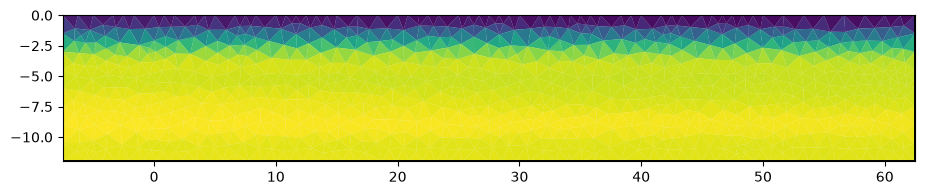

In [6]:
ax, cbar = plotting.plot_tomogram(
    manager, width=11, height=4.5, fontsize=10, rays=True,
    ray_alpha=0.25, ray_width=0.5, xlim=(-5, 60),
    ylabel='Depth below flat surface (m)')
ax.set_title('L1 preliminary P-wave velocity model and ray paths')
ax.scatter([g.source_x for g in gathers], np.zeros(len(gathers)),
           marker='v', c='red', s=35, clip_on=False, label='Sources')
ax.legend(loc='lower right')
model_figure = ax.figure
plt.show()

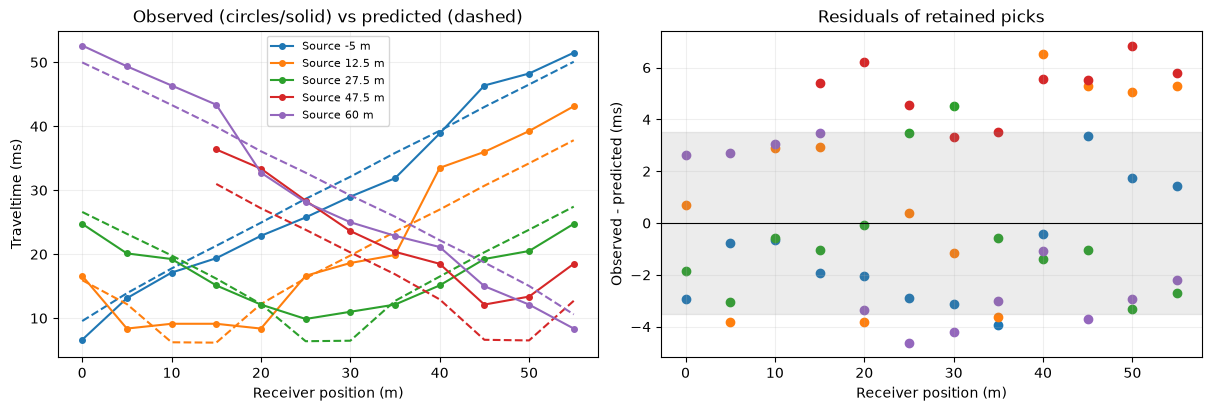

In [7]:
fit_figure, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for source, group in fit.groupby('source_x_m', sort=True):
    group = group.sort_values('receiver_x_m')
    line, = axes[0].plot(group.receiver_x_m, group.observed_ms, 'o-',
                         ms=4, label=f'Source {source:g} m')
    axes[0].plot(group.receiver_x_m, group.predicted_ms, '--', color=line.get_color())
    axes[1].scatter(group.receiver_x_m, group.residual_ms,
                    color=line.get_color(), label=f'{source:g} m')
axes[0].set(xlabel='Receiver position (m)', ylabel='Traveltime (ms)',
            title='Observed (circles/solid) vs predicted (dashed)')
axes[0].legend(fontsize=8)
axes[1].axhline(0, color='black', lw=0.8)
axes[1].axhspan(-PICK_ERROR * 1000, PICK_ERROR * 1000,
                color='grey', alpha=0.15, label='Assumed pick uncertainty')
axes[1].set(xlabel='Receiver position (m)', ylabel='Observed - predicted (ms)',
            title='Residuals of retained picks')
for ax in axes:
    ax.grid(alpha=0.2)
plt.show()

## Save results

The final cell saves the actual inversion mesh and cell velocities (not an interpolated image), retained picks in `.sgt` format for Refrainv, diagnostic tables, figures, and run settings. Re-running overwrites these files in `OUTPUT_FOLDER`. The CSV `elevation_m` coordinate is negative below the assumed flat surface; `depth_m` is positive downward. These preliminary results do not establish lithology or engineering properties.

In [8]:
import json
import obspy

OUTPUT_FOLDER.mkdir(parents=True, exist_ok=True)
centers = np.array([[c.center().x(), c.center().y()] for c in manager.paraDomain.cells()])
model_table = pd.DataFrame({'x_m': centers[:, 0], 'elevation_m': centers[:, 1],
                            'depth_m': -centers[:, 1], 'vp_m_s': velocity})
model_table.to_csv(OUTPUT_FOLDER / 'L1_velocity_cells.csv', index=False)
fit.to_csv(OUTPUT_FOLDER / 'L1_traveltime_fit.csv', index=False)
summary.to_csv(OUTPUT_FOLDER / 'L1_inversion_summary.csv', index=False)
rejected.to_csv(OUTPUT_FOLDER / 'L1_rejected_picks.csv', index=False)
manager.paraDomain.save(str(OUTPUT_FOLDER / 'L1_mesh.bms'))
np.save(OUTPUT_FOLDER / 'L1_velocity.npy', velocity)
refraction.export_refrapy_picks(data_clean, OUTPUT_FOLDER / 'L1_picks.sgt')
model_figure.savefig(OUTPUT_FOLDER / 'L1_velocity_model.png', dpi=180, bbox_inches='tight')
fit_figure.savefig(OUTPUT_FOLDER / 'L1_traveltime_fit.png', dpi=180, bbox_inches='tight')
settings = dict(
    input_files=[str(DATA_FOLDER / g.filename) for g in gathers],
    source_x_overrides=SOURCE_X_OVERRIDES,
    pick_overrides=[dict(shot_index=i, receiver_index=j,
                         time_s=None if np.isnan(t) else float(t))
                    for (i, j), t in PICK_OVERRIDES.items()],
    picking=dict(v_min=150.0, v_max=1500.0, noise_window=0.010, threshold=3.0),
    pick_error_s=PICK_ERROR, rejection_threshold_s=MAX_RESIDUAL,
    mesh=MESH_PARAMETERS, inversion=INVERSION_PARAMETERS,
    versions=dict(python=sys.version, pygimli=pg.__version__, numpy=np.__version__,
                  obspy=obspy.__version__),
    status='Preliminary automatic picks; flat 2D geometry; review required')
(OUTPUT_FOLDER / 'L1_settings.json').write_text(json.dumps(settings, indent=2, allow_nan=False) + '\n')
print(f'Results saved to {OUTPUT_FOLDER.resolve()}')
display(model_table.head())

Results saved to /home/orincon/seismic-refraction-analysis/L1/refrapy_inversion


,x_m,elevation_m,depth_m,vp_m_s
0,-2.663094,-1.445005,1.445005,766.180969
1,-0.652436,-1.885625,1.885625,936.971469
2,30.178316,-0.764319,0.764319,487.775531
3,26.251000,-0.259376,0.259376,383.957067
4,23.457140,-0.601706,0.601706,448.932962
